<p style="text-align:center">
    <a href="https://skills.network" target="_blank">
    <img src="https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/assets/logos/SN_web_lightmode.png" width="200" alt="Skills Network Logo"  />
    </a>
</p>


# **Finding Outliers**


Estimated time needed: **30** minutes


In this lab, you will work with a cleaned dataset to perform exploratory data analysis or EDA. 
You will explore the distribution of key variables and focus on identifying outliers in this lab.


## Objectives


In this lab, you will perform the following:


-  Analyze the distribution of key variables in the dataset.

-  Identify and remove outliers using statistical methods.

-  Perform relevant statistical and correlation analysis.


#### Install and import the required libraries


In [1]:
!pip install pandas
!pip install matplotlib
!pip install seaborn

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

<h3>Step 1: Load and Explore the Dataset</h3>


Load the dataset into a DataFrame and examine the structure of the data.


In [2]:
file_url = "https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/n01PQ9pSmiRX6520flujwQ/survey-data.csv"

#Create the dataframe
df = pd.read_csv(file_url)

#Display the top 10 records
df.head()


,ResponseId,MainBranch,Age,Employment,RemoteWork,Check,CodingActivities,EdLevel,LearnCode,LearnCodeOnline,...,JobSatPoints_6,JobSatPoints_7,JobSatPoints_8,JobSatPoints_9,JobSatPoints_10,JobSatPoints_11,SurveyLength,SurveyEase,ConvertedCompYearly,JobSat
0,1,I am a developer by profession,Under 18 years old,"Employed, full-time",Remote,Apples,Hobby,Primary/elementary school,Books / Physical media,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2,I am a developer by profession,35-44 years old,"Employed, full-time",Remote,Apples,Hobby;Contribute to open-source projects;Other...,"Bachelor’s degree (B.A., B.S., B.Eng., etc.)",Books / Physical media;Colleague;On the job tr...,Technical documentation;Blogs;Books;Written Tu...,...,0.0,0.0,0.0,0.0,0.0,0.0,NaN,NaN,NaN,NaN
2,3,I am a developer by profession,45-54 years old,"Employed, full-time",Remote,Apples,Hobby;Contribute to open-source projects;Other...,"Master’s degree (M.A., M.S., M.Eng., MBA, etc.)",Books / Physical media;Colleague;On the job tr...,Technical documentation;Blogs;Books;Written Tu...,...,NaN,NaN,NaN,NaN,NaN,NaN,Appropriate in length,Easy,NaN,NaN
3,4,I am learning to code,18-24 years old,"Student, full-time",NaN,Apples,NaN,Some college/university study without earning ...,"Other online resources (e.g., videos, blogs, f...",Stack Overflow;How-to videos;Interactive tutorial,...,NaN,NaN,NaN,NaN,NaN,NaN,Too long,Easy,NaN,NaN
4,5,I am a developer by profession,18-24 years old,"Student, full-time",NaN,Apples,NaN,"Secondary school (e.g. American high school, G...","Other online resources (e.g., videos, blogs, f...",Technical documentation;Blogs;Written Tutorial...,...,NaN,NaN,NaN,NaN,NaN,NaN,Too short,Easy,NaN,NaN


<h3>Step 2: Plot the Distribution of Industry</h3>


Explore how respondents are distributed across different industries.

- Plot a bar chart to visualize the distribution of respondents by industry.

- Highlight any notable trends.


Missing Industry values: 36579
Industry
Software Development                          11918
Other:                                         3077
Fintech                                        1641
Internet, Telecomm or Information Services     1629
Banking/Financial Services                     1371
Healthcare                                     1277
Manufacturing                                  1265
Retail and Consumer Services                   1264
Government                                      962
Media & Advertising Services                    894
Higher Education                                890
Transportation, or Supply Chain                 859
Computer Systems Design and Services            844
Energy                                          578
Insurance                                       389
Name: count, dtype: int64

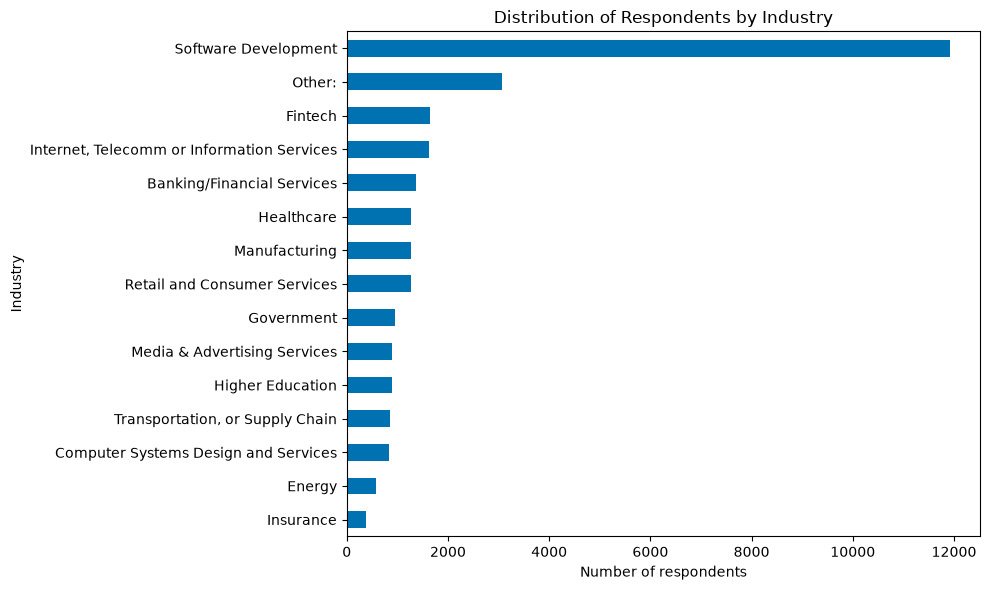

In [3]:
##Write your code here
# Step 2: Distribution of respondents by Industry
print("Missing Industry values:", df["Industry"].isnull().sum())
industry_counts = df["Industry"].value_counts()
print(industry_counts)
# Bar chart of the distribution
plt.figure(figsize=(10, 6))
industry_counts.sort_values().plot(kind="barh", color="#0072B2")
plt.title("Distribution of Respondents by Industry")
plt.xlabel("Number of respondents")
plt.ylabel("Industry")
plt.tight_layout()
plt.show()

<h3>Step 3: Identify High Compensation Outliers</h3>


Identify respondents with extremely high yearly compensation.

- Calculate basic statistics (mean, median, and standard deviation) for `ConvertedCompYearly`.

- Identify compensation values exceeding a defined threshold (e.g., 3 standard deviations above the mean).


In [4]:
##Write your code here
# Step 3: Basic statistics for ConvertedCompYearly
comp = df["ConvertedCompYearly"]
comp_mean = comp.mean()
comp_median = comp.median()
comp_std = comp.std()

print("Mean:  ", round(comp_mean, 2))
print("Median:", comp_median)
print("Std:   ", round(comp_std, 2))
# Identify outliers: compensation more than 3 standard deviations above the mean
threshold = comp_mean + 3 * comp_std
print("Threshold (mean + 3 std):", round(threshold, 2))

outliers = df[df["ConvertedCompYearly"] > threshold]
print("Number of outliers:", outliers.shape[0])
print(outliers["ConvertedCompYearly"].describe())
print(outliers[["ResponseId", "Country", "Employment", "ConvertedCompYearly"]].sort_values("ConvertedCompYearly", ascending=False).head(10))

Mean:   86155.29
Median: 65000.0
Std:    186756.97
Threshold (mean + 3 std): 646426.21
Number of outliers: 89
count    8.900000e+01
mean     1.623895e+06
std      2.366560e+06
min      6.500000e+05
25%      7.500000e+05
50%      1.000000e+06
75%      1.332930e+06
max      1.625660e+07
Name: ConvertedCompYearly, dtype: float64
       ResponseId       Country  \
15837       15838      Ethiopia   
12723       12724  South Africa   
28379       28380        Taiwan   
17593       17594        Brazil   
17672       17673       Ukraine   
19267       19268         India   
23694       23695      Pakistan   
33720       33721        Brazil   
34523       34524      Pakistan   
13763       13764     Australia   

                                              Employment  ConvertedCompYearly  
15837  Independent contractor, freelancer, or self-em...           16256603.0  
12723  Employed, full-time;Independent contractor, fr...           13818022.0  
28379                                Employed,

<h3>Step 4: Detect Outliers in Compensation</h3>


Identify outliers in the `ConvertedCompYearly` column using the IQR method.

- Calculate the Interquartile Range (IQR).

- Determine the upper and lower bounds for outliers.

- Count and visualize outliers using a box plot.


Q1: 32712.0
Q3: 107971.5
IQR: 75259.5
Lower bound: -80177.25
Upper bound: 220860.75
Outliers below the lower bound: 0
Outliers above the upper bound: 978
Total outliers: 978
Share of respondents with compensation data: 4.2 %

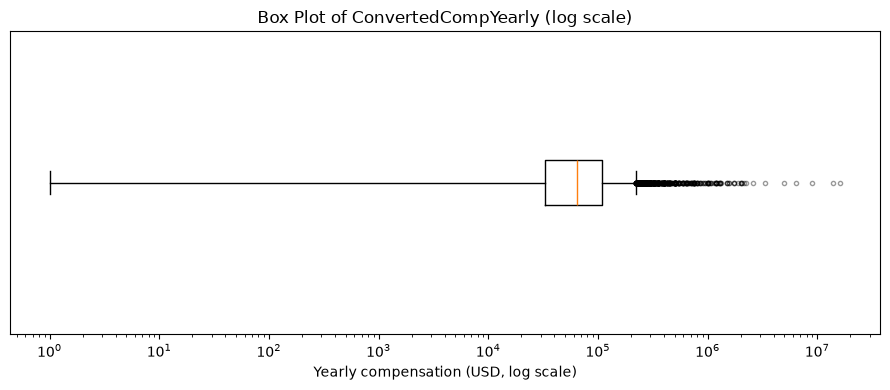

In [8]:
##Write your code here
# Step 4: Calculate the IQR and the outlier bounds
comp = df["ConvertedCompYearly"].dropna()

q1 = comp.quantile(0.25)
q3 = comp.quantile(0.75)
iqr = q3 - q1

lower_bound = q1 - 1.5 * iqr
upper_bound = q3 + 1.5 * iqr

print("Q1:", q1)
print("Q3:", q3)
print("IQR:", iqr)
print("Lower bound:", lower_bound)
print("Upper bound:", upper_bound)
# Count the outliers
lower_outliers = comp[comp < lower_bound]
upper_outliers = comp[comp > upper_bound]

print("Outliers below the lower bound:", lower_outliers.shape[0])
print("Outliers above the upper bound:", upper_outliers.shape[0])
print("Total outliers:", lower_outliers.shape[0] + upper_outliers.shape[0])
print("Share of respondents with compensation data:", round((lower_outliers.shape[0] + upper_outliers.shape[0]) / len(comp) * 100, 1), "%")
# Box plot (log scale so the box stays readable despite extreme values)

plt.figure(figsize=(9, 4))
plt.boxplot(comp, orientation="horizontal", flierprops={"marker": "o", "markersize": 3, "alpha": 0.4})
plt.xscale("log")
plt.title("Box Plot of ConvertedCompYearly (log scale)")
plt.xlabel("Yearly compensation (USD, log scale)")
plt.yticks([])
plt.tight_layout()
plt.show()

<h3>Step 5: Remove Outliers and Create a New DataFrame</h3>


Remove outliers from the dataset.

- Create a new DataFrame excluding rows with outliers in `ConvertedCompYearly`.
- Validate the size of the new DataFrame.


In [10]:
##Write your code here
# Validate the new DataFrame
# Step 5: Create a new DataFrame without compensation outliers
# Rows with missing compensation are kept, because a missing value is not an outlier
is_outlier = (df["ConvertedCompYearly"] < lower_bound) | (df["ConvertedCompYearly"] > upper_bound)
df_no_outliers = df[~is_outlier].copy()

print("Original shape:", df.shape)
print("New shape:", df_no_outliers.shape)
print("Rows removed:", df.shape[0] - df_no_outliers.shape[0])
remaining_outliers = df_no_outliers[(df_no_outliers["ConvertedCompYearly"] > upper_bound) |
                                    (df_no_outliers["ConvertedCompYearly"] < lower_bound)]
print("Outliers remaining:", remaining_outliers.shape[0])
print("Max ConvertedCompYearly now:", df_no_outliers["ConvertedCompYearly"].max())
print("Mean ConvertedCompYearly now:", round(df_no_outliers["ConvertedCompYearly"].mean(), 2))
print("Median ConvertedCompYearly now:", df_no_outliers["ConvertedCompYearly"].median())

Original shape: (65437, 114)
New shape: (64459, 114)
Rows removed: 978
Outliers remaining: 0
Max ConvertedCompYearly now: 220207.0
Mean ConvertedCompYearly now: 71347.2
Median ConvertedCompYearly now: 63694.0

<h3>Step 6: Correlation Analysis</h3>


Analyze the correlation between `Age` (transformed) and other numerical columns.

- Map the `Age` column to approximate numeric values.

- Compute correlations between `Age` and other numeric variables.

- Visualize the correlation matrix.


Age
25-34 years old       23603
35-44 years old       14570
18-24 years old       14074
45-54 years old        6068
Under 18 years old     2567
55-64 years old        2494
65 years or older       762
Prefer not to say       321
Name: count, dtype: int64
Age_numeric missing: 321
WorkExp                0.849
ConvertedCompYearly    0.370
JobSat                 0.068
JobSatPoints_1        -0.029
JobSatPoints_8        -0.046
JobSatPoints_6        -0.049
JobSatPoints_4        -0.075
JobSatPoints_9        -0.080
JobSatPoints_7        -0.081
JobSatPoints_5        -0.101
JobSatPoints_11       -0.106
JobSatPoints_10       -0.112
Name: Age_numeric, dtype: float64

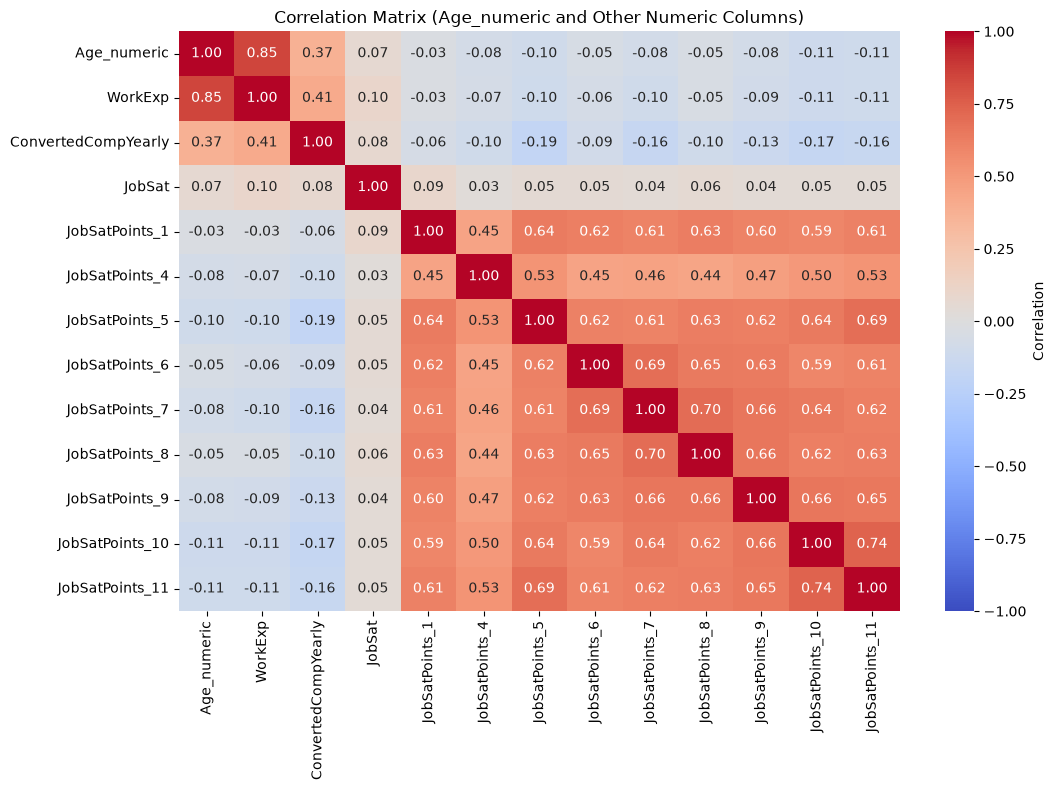

In [12]:
##Write your code here
# Step 6: Map Age to approximate numeric values (midpoint of each range)
age_mapping = {
    "Under 18 years old": 16,
    "18-24 years old": 21,
    "25-34 years old": 29.5,
    "35-44 years old": 39.5,
    "45-54 years old": 49.5,
    "55-64 years old": 59.5,
    "65 years or older": 70
}

df_corr = df_no_outliers.copy()
df_corr["Age_numeric"] = df_corr["Age"].map(age_mapping)

print(df_corr["Age"].value_counts())
print("Age_numeric missing:", df_corr["Age_numeric"].isnull().sum())
# Compute correlations between Age_numeric and the other numeric columns
numeric_cols = ["Age_numeric", "WorkExp", "ConvertedCompYearly", "JobSat",
                "JobSatPoints_1", "JobSatPoints_4", "JobSatPoints_5", "JobSatPoints_6",
                "JobSatPoints_7", "JobSatPoints_8", "JobSatPoints_9", "JobSatPoints_10",
                "JobSatPoints_11"]

corr_matrix = df_corr[numeric_cols].corr()
print(corr_matrix["Age_numeric"].drop("Age_numeric").sort_values(ascending=False).round(3))
# Visualize the correlation matrix as a heatmap

plt.figure(figsize=(11, 8))
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="coolwarm", center=0, vmin=-1, vmax=1,
            cbar_kws={"label": "Correlation"})
plt.title("Correlation Matrix (Age_numeric and Other Numeric Columns)")
plt.tight_layout()
plt.show()

<h3> Summary </h3>


In this lab, you developed essential skills in **Exploratory Data Analysis (EDA)** with a focus on outlier detection and removal. Specifically, you:


- Loaded and explored the dataset to understand its structure.

- Analyzed the distribution of respondents across industries.

- Identified and removed high compensation outliers using statistical thresholds and the Interquartile Range (IQR) method.

- Performed correlation analysis, including transforming the `Age` column into numeric values for better analysis.


<!--
## Change Log
|Date (YYYY-MM-DD)|Version|Changed By|Change Description|
|-|-|-|-|               
|2024-10-1|1.1|Madhusudan Moole|Reviewed and updated lab|                                                                                    
|2024-09-29|1.0|Raghul Ramesh|Created lab|
--!>


Copyright © IBM Corporation. All rights reserved.
